# X3D Crime Detection Model - Violence/Theft/Normal Classification
## X3D (Expanding Architecture for Video) with Full Training Pipeline and Performance Visualization

## 1. Import Required Libraries

In [25]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import gc
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.9.0+cu126
Torchvision version: 0.24.0+cu126
CUDA available: True
GPU: Tesla P100-PCIE-16GB


## 2. Define Dataset Paths and Classes

In [26]:
RWF       = "/kaggle/input/datasets/daniazehra/rwf-2000/RWF-2000"
UCF_CRIME = "/kaggle/input/datasets/alirakhmaev/ucf-crime-full"
CAMNUVEOM = "/kaggle/input/datasets/mohamedelattar15/camnuveom1/camnuveom/videos/samples/training"

MAIN_CLASSES = ['violence', 'theft', 'normal']

# UCF-Crime mapping — identical to model-1.ipynb (Swin3D reference)
# Only theft + normal from UCF. Violence comes from RWF-2000 only.
UCF_TO_MAIN_CLASS = {
    'Shoplifting': 'theft',
    'Stealing':    'theft',
    'Robbery':     'theft',
    'Burglary':    'theft',
    'Normal':      'normal',
}

print(f"Main Classes: {MAIN_CLASSES}")
print(f"Number of Classes: {len(MAIN_CLASSES)}")

Main Classes: ['violence', 'theft', 'normal']
Number of Classes: 3


## 3. Data Loading Functions

In [27]:
def load_camnuveom():
    """Load CAMNUVEON dataset"""
    rows = []
    for cls in ["anomaly", "normal"]:
        class_dir = os.path.join(CAMNUVEOM, cls)
        if not os.path.exists(class_dir):
            print(f"Directory not found: {class_dir}")
            continue

        videos = glob.glob(os.path.join(class_dir, "*.mp4"))

        main_label = "theft" if cls == "anomaly" else "normal"

        for video_path in videos:
            rows.append({
                'clip_path':      video_path,
                'main_label':     main_label,
                'sub_label':      main_label,
                'dataset':        'camnuveon',
                'original_class': cls,
                'split':          'unknown'
            })

    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from CAMNUVEON")
    return df


def load_rwf():
    """Load RWF-2000 dataset"""
    rows = []
    for split in ["train", "val"]:
        for cls in ["Fight", "NonFight"]:
            class_dir = os.path.join(RWF, split, cls)
            if not os.path.exists(class_dir):
                print(f"Directory not found: {class_dir}")
                continue

            videos = glob.glob(os.path.join(class_dir, "*.avi"))
            main_label = "violence" if cls == "Fight" else "normal"

            for video_path in videos:
                rows.append({
                    'clip_path':      video_path,
                    'main_label':     main_label,
                    'sub_label':      main_label,
                    'dataset':        'RWF-2000',
                    'original_class': cls,
                    'split':          split
                })

    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from RWF-2000")
    return df


def load_ucf():
    """Load UCF-Crime dataset"""
    if not os.path.exists(UCF_CRIME):
        print("UCF-Crime path not found")
        return None

    class_folders = [d for d in os.listdir(UCF_CRIME)
                     if os.path.isdir(os.path.join(UCF_CRIME, d))]
    print(f"Found {len(class_folders)} class folders in UCF-Crime")

    rows = []
    for class_name in class_folders:
        class_path = os.path.join(UCF_CRIME, class_name)
        main_label = UCF_TO_MAIN_CLASS.get(class_name)
        if main_label is None:
            continue

        videos = glob.glob(os.path.join(class_path, "*.mp4")) + \
                 glob.glob(os.path.join(class_path, "*.avi"))

        if not videos:
            print(f"  Warning: No videos found in {class_name}")
            continue

        for video_path in videos:
            rows.append({
                'clip_path':      video_path,
                'main_label':     main_label,
                'sub_label':      class_name.lower(),
                'dataset':        'UCF-Crime',
                'original_class': class_name,
                'split':          'unknown'
            })

    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from UCF-Crime")
    return df

## 4. Load and Merge Datasets

In [28]:
print("\n" + "="*60)
print("LOADING DATASETS")
print("="*60)

rwf_df = load_rwf()
ucf_df = load_ucf()
cam_df = load_camnuveom()

# Merge datasets
df = pd.concat([rwf_df, ucf_df, cam_df], ignore_index=True)
df = df[df['main_label'].isin(MAIN_CLASSES)].copy()

print(f"\nTotal videos loaded: {len(df)}")
print("\n" + "="*60)
print("DATASET DISTRIBUTION")
print("="*60)

for cls in MAIN_CLASSES:
    count = len(df[df['main_label'] == cls])
    percentage = (count / len(df)) * 100
    print(f"  {cls}: {count:4d} videos ({percentage:5.1f}%)")


LOADING DATASETS
✓ Loaded 2000 videos from RWF-2000
Found 14 class folders in UCF-Crime
✓ Loaded 400 videos from UCF-Crime
✓ Loaded 874 videos from CAMNUVEON

Total videos loaded: 3274

DATASET DISTRIBUTION
  violence: 1000 videos ( 30.5%)
  theft:  837 videos ( 25.6%)
  normal: 1437 videos ( 43.9%)


## 5. X3D Dataset Class (Key Modifications)

**KEY MODIFICATIONS FOR X3D:**
- `num_frames = 16` — X3D-M standard temporal clip length
- `img_size = 224` — spatial resolution
- Uniform frame sampling across the full video
- UCF-Crime middle-frame optimization (crime concentrated in 25–75%)

In [29]:
class X3DCrimeDetectionDataset(Dataset):
    """Dataset class for X3D model

    KEY MODIFICATIONS FOR X3D:
    - num_frames = 16 (standard X3D temporal clip)
    - img_size = 224 (spatial resolution)
    - UCF-Crime middle-frame optimization
    - Output tensor shape: (C, T, H, W)
    """

    def __init__(self, dataframe, num_frames=16, img_size=224, is_train=True):
        self.dataframe  = dataframe.reset_index(drop=True)
        self.num_frames = num_frames   # X3D uses 16 frames
        self.img_size   = img_size
        self.is_train   = is_train

        self.label_to_idx = {label: idx for idx, label in enumerate(MAIN_CLASSES)}
        self.idx_to_label = {idx: label for label, idx in self.label_to_idx.items()}

        print(f"X3D Dataset initialized: {len(self.dataframe)} samples, {len(MAIN_CLASSES)} classes")
        print(f"  Frames per video: {num_frames}")
        print(f"  Image size: {img_size}x{img_size}")
        print(f"  Processing: X3D spatio-temporal 3D convolutions")

    def __len__(self):
        return len(self.dataframe)

    def extract_frames(self, video_path):
        """Extract num_frames uniformly from video.
        For UCF-Crime: extract from middle 50% (crime concentrated there).
        """
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

            if total_frames < 1:
                cap.release()
                return None

            # UCF-Crime: crime often happens in the middle
            if 'UCF-Crime' in video_path:
                start_frame = max(0, total_frames // 4)
                end_frame   = min(total_frames, 3 * total_frames // 4)
            else:
                start_frame = 0
                end_frame   = total_frames

            if end_frame <= start_frame:
                indices = [0] * self.num_frames
            else:
                indices = np.linspace(start_frame, end_frame - 1, self.num_frames, dtype=int)

            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = cv2.resize(frame, (self.img_size, self.img_size))
                    frames.append(frame.astype(np.float32) / 255.0)
                else:
                    frames.append(np.zeros((self.img_size, self.img_size, 3), dtype=np.float32))

            cap.release()

            if len(frames) == 0:
                return None

            # Convert to tensor format (C, T, H, W)
            frames = np.stack(frames, axis=0)        # (T, H, W, C)
            frames = np.transpose(frames, (3, 0, 1, 2))  # (C, T, H, W)
            return frames

        except Exception as e:
            print(f"Error extracting frames from {video_path}: {e}")
            return None

    def __getitem__(self, idx):
        video_path = self.dataframe.loc[idx, 'clip_path']
        main_label = self.dataframe.loc[idx, 'main_label']

        frames = self.extract_frames(video_path)

        if frames is None:
            frames_tensor = torch.zeros((3, self.num_frames, self.img_size, self.img_size))
            label_idx = self.label_to_idx['normal']
        else:
            frames_tensor = torch.from_numpy(frames).float()

            # ImageNet normalization
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1, 1)
            std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1, 1)
            frames_tensor = (frames_tensor - mean) / std

            label_idx = self.label_to_idx[main_label]

        return frames_tensor, label_idx, video_path

## 6. Create Data Splits (Train/Val/Test with K-Fold)

In [30]:
# Shuffle dataset
df = df.sample(frac=1).reset_index(drop=True)
NUM_CLASSES = len(MAIN_CLASSES)

print("\n" + "="*60)
print("CREATING DATA SPLITS")
print("="*60)

# Stratified train/test split (85% train+val, 15% test)
train_val, test = train_test_split(
    df,
    test_size=0.15,
    stratify=df['main_label'],
    random_state=42
)

print(f"\nTrain+Val: {len(train_val)} samples")
print(f"Test:      {len(test)} samples")

X = train_val
y = train_val['main_label']


CREATING DATA SPLITS

Train+Val: 2782 samples
Test:      492 samples


## 7. K-Fold Cross-Validation Setup

In [31]:
# Configuration
BATCH_SIZE      = 4
NUM_WORKERS     = 2
K_FOLDS         = 2
NUM_FRAMES_X3D  = 16   # X3D standard temporal clip
IMG_SIZE_X3D    = 224

skf   = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=38)
folds = []

print("\n" + "="*60)
print("K-FOLD SPLIT CREATION")
print("="*60)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    print(f"\nFold {fold+1}/{K_FOLDS}")
    print(f"  Train: {len(train_idx)} samples")
    print(f"  Val:   {len(val_idx)} samples")

    train_df = train_val.iloc[train_idx].reset_index(drop=True)
    val_df   = train_val.iloc[val_idx].reset_index(drop=True)

    train_dataset = X3DCrimeDetectionDataset(train_df, num_frames=NUM_FRAMES_X3D, img_size=IMG_SIZE_X3D, is_train=True)
    val_dataset   = X3DCrimeDetectionDataset(val_df,   num_frames=NUM_FRAMES_X3D, img_size=IMG_SIZE_X3D, is_train=False)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)

    folds.append((train_loader, val_loader))

# Test dataset
test_dataset = X3DCrimeDetectionDataset(test, num_frames=NUM_FRAMES_X3D, img_size=IMG_SIZE_X3D, is_train=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f"\nTest dataset: {len(test)} samples")


K-FOLD SPLIT CREATION

Fold 1/2
  Train: 1391 samples
  Val:   1391 samples
X3D Dataset initialized: 1391 samples, 3 classes
  Frames per video: 16
  Image size: 224x224
  Processing: X3D spatio-temporal 3D convolutions
X3D Dataset initialized: 1391 samples, 3 classes
  Frames per video: 16
  Image size: 224x224
  Processing: X3D spatio-temporal 3D convolutions

Fold 2/2
  Train: 1391 samples
  Val:   1391 samples
X3D Dataset initialized: 1391 samples, 3 classes
  Frames per video: 16
  Image size: 224x224
  Processing: X3D spatio-temporal 3D convolutions
X3D Dataset initialized: 1391 samples, 3 classes
  Frames per video: 16
  Image size: 224x224
  Processing: X3D spatio-temporal 3D convolutions
X3D Dataset initialized: 492 samples, 3 classes
  Frames per video: 16
  Image size: 224x224
  Processing: X3D spatio-temporal 3D convolutions

Test dataset: 492 samples


## 8. X3D Model Creation (Key Architecture)

X3D expands a 2D image classification architecture along multiple axes:
- **Temporal** (number of frames)
- **Width** (channel count)
- **Bottleneck width**
- **Depth** (number of layers)

We use **X3D-M** (medium variant) pre-trained on Kinetics-400.

In [32]:
print("\n" + "="*60)
print("X3D MODEL CREATION")
print("="*60)


def create_x3d_model(num_classes=3):
    """Create and adapt X3D-M model for crime detection.

    KEY FEATURES:
    - X3D-M: Medium variant, best accuracy/efficiency trade-off
    - Pre-trained on Kinetics-400 (400 action classes)
    - Adapted for 3-class crime classification
    - Uses pytorchvideo or torchvision depending on availability
    """
    # Strategy 1: torchvision >= 0.14 ships x3d_m
    try:
        from torchvision.models.video import x3d_m
        print("Attempting to load X3D-M from torchvision...")
        model = x3d_m(weights='KINETICS400_V1')

        # X3D head: model.heads.head  (Linear over 400)
        # Replace the projection layer
        if hasattr(model, 'heads') and hasattr(model.heads, 'head'):
            in_features = model.heads.head.in_features
            model.heads.head = nn.Linear(in_features, num_classes)
            print(f"✓ Loaded X3D-M (torchvision). Head replaced: {in_features} → {num_classes}")
        else:
            # Fallback: try to find the last linear layer
            print("Warning: Non-standard head structure, searching for fc...")
            for name, module in reversed(list(model.named_modules())):
                if isinstance(module, nn.Linear):
                    in_features = module.in_features
                    # Replace using parent module traversal
                    parts = name.split('.')
                    parent = model
                    for p in parts[:-1]:
                        parent = getattr(parent, p)
                    setattr(parent, parts[-1], nn.Linear(in_features, num_classes))
                    print(f"✓ Replaced layer '{name}': {in_features} → {num_classes}")
                    break

        # Verify output shape
        with torch.no_grad():
            dummy = torch.randn(1, 3, NUM_FRAMES_X3D, IMG_SIZE_X3D, IMG_SIZE_X3D)
            out   = model(dummy)
            print(f"✓ Output shape verified: {out.shape}")

        return model

    except Exception as e:
        print(f"torchvision X3D-M failed: {e}")

    # Strategy 2: pytorchvideo (Facebook Research)
    try:
        import pytorchvideo.models as pv_models
        print("Attempting to load X3D-M from pytorchvideo...")
        model = torch.hub.load('facebookresearch/pytorchvideo', 'x3d_m', pretrained=True)

        # Replace classification head
        in_features = model.blocks[-1].proj.in_features
        model.blocks[-1].proj = nn.Linear(in_features, num_classes)
        print(f"✓ Loaded X3D-M (pytorchvideo). Head replaced: {in_features} → {num_classes}")

        with torch.no_grad():
            dummy = torch.randn(1, 3, NUM_FRAMES_X3D, IMG_SIZE_X3D, IMG_SIZE_X3D)
            out   = model(dummy)
            print(f"✓ Output shape verified: {out.shape}")

        return model

    except Exception as e2:
        print(f"pytorchvideo X3D-M failed: {e2}")

    # Strategy 3: Custom lightweight X3D-inspired 3D CNN fallback
    print("Creating custom X3D-inspired 3D CNN fallback...")

    class X3DBlock(nn.Module):
        """Basic X3D depthwise-separable 3D conv block"""
        def __init__(self, in_ch, out_ch, t_stride=1):
            super().__init__()
            mid_ch = out_ch // 4
            self.conv1 = nn.Conv3d(in_ch,  mid_ch, kernel_size=1, bias=False)
            self.bn1   = nn.BatchNorm3d(mid_ch)
            self.conv2 = nn.Conv3d(mid_ch, mid_ch,
                                   kernel_size=(3, 3, 3),
                                   stride=(t_stride, 1, 1),
                                   padding=(1, 1, 1),
                                   groups=mid_ch,
                                   bias=False)
            self.bn2   = nn.BatchNorm3d(mid_ch)
            self.conv3 = nn.Conv3d(mid_ch, out_ch, kernel_size=1, bias=False)
            self.bn3   = nn.BatchNorm3d(out_ch)
            self.relu  = nn.ReLU(inplace=True)
            self.skip  = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, kernel_size=1,
                          stride=(t_stride, 1, 1), bias=False),
                nn.BatchNorm3d(out_ch)
            ) if in_ch != out_ch or t_stride != 1 else nn.Identity()

        def forward(self, x):
            out = self.relu(self.bn1(self.conv1(x)))
            out = self.relu(self.bn2(self.conv2(out)))
            out = self.bn3(self.conv3(out))
            return self.relu(out + self.skip(x))

    class X3DFallback(nn.Module):
        def __init__(self, num_classes=3):
            super().__init__()
            self.stem = nn.Sequential(
                nn.Conv3d(3, 24, kernel_size=(1, 3, 3), stride=(1, 2, 2), padding=(0, 1, 1), bias=False),
                nn.BatchNorm3d(24),
                nn.ReLU(inplace=True)
            )
            self.stage1 = X3DBlock(24,  48)
            self.stage2 = X3DBlock(48,  96,  t_stride=2)
            self.stage3 = X3DBlock(96,  192, t_stride=2)
            self.stage4 = X3DBlock(192, 432)
            self.pool   = nn.AdaptiveAvgPool3d(1)
            self.drop   = nn.Dropout(0.5)
            self.fc     = nn.Linear(432, num_classes)

        def forward(self, x):
            x = self.stem(x)
            x = self.stage1(x)
            x = self.stage2(x)
            x = self.stage3(x)
            x = self.stage4(x)
            x = self.pool(x).flatten(1)
            x = self.drop(x)
            return self.fc(x)

    model = X3DFallback(num_classes)
    with torch.no_grad():
        dummy = torch.randn(1, 3, NUM_FRAMES_X3D, IMG_SIZE_X3D, IMG_SIZE_X3D)
        out   = model(dummy)
        print(f"✓ X3D Fallback output shape: {out.shape}")
    return model


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")

model = create_x3d_model(NUM_CLASSES)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"\n✓ Model: {model.__class__.__name__}")
print(f"  Total parameters: {total_params:,}")
print(f"  Output classes: {NUM_CLASSES}")


X3D MODEL CREATION

Using device: cuda
torchvision X3D-M failed: cannot import name 'x3d_m' from 'torchvision.models.video' (/usr/local/lib/python3.12/dist-packages/torchvision/models/video/__init__.py)
pytorchvideo X3D-M failed: No module named 'pytorchvideo'
Creating custom X3D-inspired 3D CNN fallback...
✓ X3D Fallback output shape: torch.Size([1, 3])

✓ Model: X3DFallback
  Total parameters: 203,691
  Output classes: 3


## 9. Training Functions

In [33]:
def train_epoch(model, loader, optimizer, criterion, device, epoch):
    """Train for one epoch with per-class tracking"""
    model.train()
    total_loss = 0.0
    correct = 0
    total   = 0

    class_correct = {cls: 0 for cls in MAIN_CLASSES}
    class_total   = {cls: 0 for cls in MAIN_CLASSES}

    pbar = tqdm(loader, desc=f'Train Epoch {epoch}')
    for batch_idx, (inputs, labels, paths) in enumerate(pbar):
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(inputs)
        loss    = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        _, predicted = outputs.max(1)
        total   += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        total_loss += loss.item()

        for i in range(len(labels)):
            true_class = MAIN_CLASSES[labels[i].item()]
            class_total[true_class] += 1
            if predicted[i] == labels[i]:
                class_correct[true_class] += 1

        pbar.set_postfix({
            'Loss': f'{total_loss/(batch_idx+1):.4f}',
            'Acc':  f'{100.*correct/total:.1f}%'
        })

    avg_loss = total_loss / len(loader)
    accuracy = 100. * correct / total

    print(f"  Per-class training accuracy:")
    for cls in MAIN_CLASSES:
        if class_total[cls] > 0:
            cls_acc = 100. * class_correct[cls] / class_total[cls]
            print(f"    {cls}: {cls_acc:.1f}% ({class_correct[cls]}/{class_total[cls]})")

    return avg_loss, accuracy


def validate(model, loader, criterion, device, mode='val'):
    """Validate model performance"""
    model.eval()
    total_loss = 0.0
    correct = 0
    total   = 0

    class_correct = {cls: 0 for cls in MAIN_CLASSES}
    class_total   = {cls: 0 for cls in MAIN_CLASSES}

    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels, paths in tqdm(loader, desc=f'{mode.capitalize()} Eval'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss    = criterion(outputs, labels)

            _, predicted = outputs.max(1)
            total   += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            total_loss += loss.item()

            for i in range(len(labels)):
                true_class = MAIN_CLASSES[labels[i].item()]
                class_total[true_class] += 1
                if predicted[i] == labels[i]:
                    class_correct[true_class] += 1

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = 100. * correct / total

    print(f"  {mode.capitalize()} Loss: {avg_loss:.4f}, Accuracy: {accuracy:.1f}%")
    print(f"  Per-class {mode} accuracy:")
    for cls in MAIN_CLASSES:
        if class_total[cls] > 0:
            cls_acc = 100. * class_correct[cls] / class_total[cls]
            print(f"    {cls}: {cls_acc:.1f}% ({class_correct[cls]}/{class_total[cls]})")

    return avg_loss, accuracy, all_preds, all_labels

## 10. Initialize Loss Function

In [34]:
criterion = nn.CrossEntropyLoss()
print(f"Loss function: {criterion.__class__.__name__}")

Loss function: CrossEntropyLoss


## 11. Training Loop with K-Fold Cross-Validation

In [35]:
EPOCHS       = 5
fold_results = []

print("\n" + "="*60)
print("TRAINING X3D MODEL WITH K-FOLD CROSS-VALIDATION")
print("="*60)

for fold, (train_loader, val_loader) in enumerate(folds):
    print(f"\n{'='*60}")
    print(f"FOLD {fold+1}/{K_FOLDS}")
    print(f"{'='*60}")

    # Reinitialize fresh model for each fold
    model = create_x3d_model(NUM_CLASSES)
    model = model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

    best_val_acc      = 0
    early_stop_counter = 0
    patience          = 3
    fold_train_losses = []
    fold_val_losses   = []
    fold_train_accs   = []
    fold_val_accs     = []

    for epoch in range(1, EPOCHS + 1):
        print(f"\nEpoch {epoch}/{EPOCHS}")

        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device, epoch)
        fold_train_losses.append(train_loss)
        fold_train_accs.append(train_acc)

        val_loss, val_acc, _, _ = validate(model, val_loader, criterion, device, 'val')
        fold_val_losses.append(val_loss)
        fold_val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            early_stop_counter = 0
            torch.save(model.state_dict(), f"/kaggle/working/best_x3d_fold{fold+1}.pth")
            print(f"  ✓ Best model saved (Val Acc: {val_acc:.2f}%)")
        else:
            early_stop_counter += 1
            print(f"  ✗ No improvement ({early_stop_counter}/{patience})")

        if early_stop_counter >= patience:
            print(f"\n  EARLY STOPPING TRIGGERED")
            break

        scheduler.step()

    fold_results.append({
        'fold':         fold + 1,
        'best_val_acc': best_val_acc,
        'train_losses': fold_train_losses,
        'val_losses':   fold_val_losses,
        'train_accs':   fold_train_accs,
        'val_accs':     fold_val_accs
    })

    print(f"\nFold {fold+1} completed — Best Val Acc: {best_val_acc:.2f}%")
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


TRAINING X3D MODEL WITH K-FOLD CROSS-VALIDATION

FOLD 1/2
torchvision X3D-M failed: cannot import name 'x3d_m' from 'torchvision.models.video' (/usr/local/lib/python3.12/dist-packages/torchvision/models/video/__init__.py)
pytorchvideo X3D-M failed: No module named 'pytorchvideo'
Creating custom X3D-inspired 3D CNN fallback...
✓ X3D Fallback output shape: torch.Size([1, 3])

Epoch 1/5


Train Epoch 1: 100%|██████████| 347/347 [05:39<00:00,  1.02it/s, Loss=1.0671, Acc=44.5%]


  Per-class training accuracy:
    violence: 31.6% (134/424)
    theft: 13.0% (46/353)
    normal: 71.7% (438/611)


Val Eval: 100%|██████████| 348/348 [05:36<00:00,  1.04it/s]


  Val Loss: 0.9920, Accuracy: 51.4%
  Per-class val accuracy:
    violence: 43.5% (185/425)
    theft: 12.6% (45/356)
    normal: 79.5% (485/610)
  ✓ Best model saved (Val Acc: 51.40%)

Epoch 2/5


...

  Val Loss: 0.9259, Accuracy: 56.6%
  Per-class val accuracy:
    violence: 47.5% (202/425)
    theft: 37.5% (133/355)
    normal: 74.1% (453/611)
  ✓ Best model saved (Val Acc: 56.65%)

Epoch 5/5


Train Epoch 5: 100%|██████████| 347/347 [05:42<00:00,  1.01it/s, Loss=0.9601, Acc=54.1%]


  Per-class training accuracy:
    violence: 42.6% (181/425)
    theft: 36.4% (129/354)
    normal: 72.4% (441/609)


Val Eval: 100%|██████████| 348/348 [05:32<00:00,  1.05it/s]


  Val Loss: 0.9245, Accuracy: 56.6%
  Per-class val accuracy:
    violence: 48.7% (207/425)
    theft: 35.8% (127/355)
    normal: 74.1% (453/611)
  ✗ No improvement (1/3)

Fold 2 completed — Best Val Acc: 56.65%


## 12. Select Best Fold and Evaluate on Test Set

In [36]:
best_fold_idx = np.argmax([r['best_val_acc'] for r in fold_results])
best_fold     = fold_results[best_fold_idx]['fold']
best_fold_acc = fold_results[best_fold_idx]['best_val_acc']

print("\n" + "="*60)
print("K-FOLD RESULTS SUMMARY")
print("="*60)
for result in fold_results:
    print(f"Fold {result['fold']}: Best Val Acc = {result['best_val_acc']:.2f}%")

print(f"\n{'='*60}")
print(f"BEST FOLD: {best_fold} with Val Acc = {best_fold_acc:.2f}%")
print(f"{'='*60}")

# Load best fold model
best_model_path = f"/kaggle/working/best_x3d_fold{best_fold}.pth"
best_model = create_x3d_model(NUM_CLASSES)
best_model.load_state_dict(torch.load(best_model_path))
best_model = best_model.to(device)
print(f"\n✓ Loaded best model from: {best_model_path}")

# Evaluate on test set
print("\n" + "="*60)
print("TEST SET EVALUATION")
print("="*60)
test_loss, test_acc, test_preds, test_labels = validate(
    best_model, test_loader, criterion, device, mode="test"
)

print(f"\nFinal Test Accuracy: {test_acc:.2f}%")


K-FOLD RESULTS SUMMARY
Fold 1: Best Val Acc = 56.36%
Fold 2: Best Val Acc = 56.65%

BEST FOLD: 2 with Val Acc = 56.65%
torchvision X3D-M failed: cannot import name 'x3d_m' from 'torchvision.models.video' (/usr/local/lib/python3.12/dist-packages/torchvision/models/video/__init__.py)
pytorchvideo X3D-M failed: No module named 'pytorchvideo'
Creating custom X3D-inspired 3D CNN fallback...
✓ X3D Fallback output shape: torch.Size([1, 3])

✓ Loaded best model from: /kaggle/working/best_x3d_fold2.pth

TEST SET EVALUATION


Test Eval: 100%|██████████| 123/123 [02:00<00:00,  1.02it/s]

  Test Loss: 0.9528, Accuracy: 52.0%
  Per-class test accuracy:
    violence: 44.0% (66/150)
    theft: 31.0% (39/126)
    normal: 69.9% (151/216)

Final Test Accuracy: 52.03%


## 13. Detailed Performance Metrics

In [37]:
print("\n" + "="*60)
print("DETAILED CLASSIFICATION REPORT")
print("="*60)

print(classification_report(
    test_labels,
    test_preds,
    target_names=MAIN_CLASSES,
    digits=4
))


DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

    violence     0.5000    0.4400    0.4681       150
       theft     0.4382    0.3095    0.3628       126
      normal     0.5572    0.6991    0.6201       216

    accuracy                         0.5203       492
   macro avg     0.4985    0.4829    0.4837       492
weighted avg     0.5093    0.5203    0.5079       492



## 14. Confusion Matrix Visualization

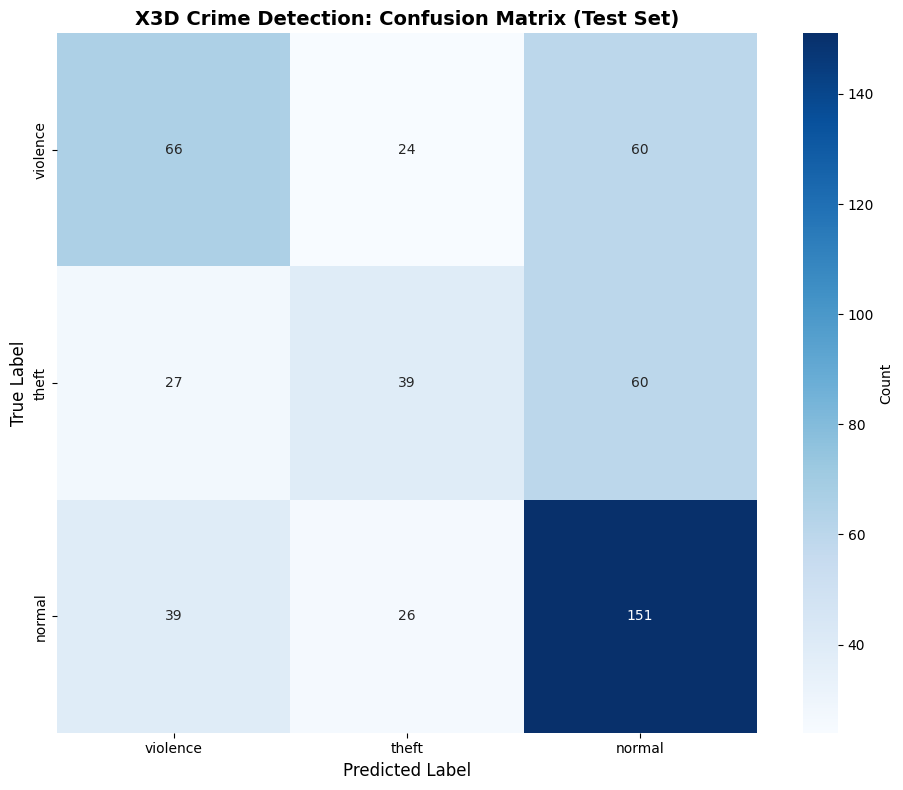


✓ Confusion matrix saved


In [38]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=MAIN_CLASSES,
    yticklabels=MAIN_CLASSES,
    cbar_kws={'label': 'Count'},
    square=True
)
plt.title('X3D Crime Detection: Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/x3d_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Confusion matrix saved")

## 15. Training History Visualization

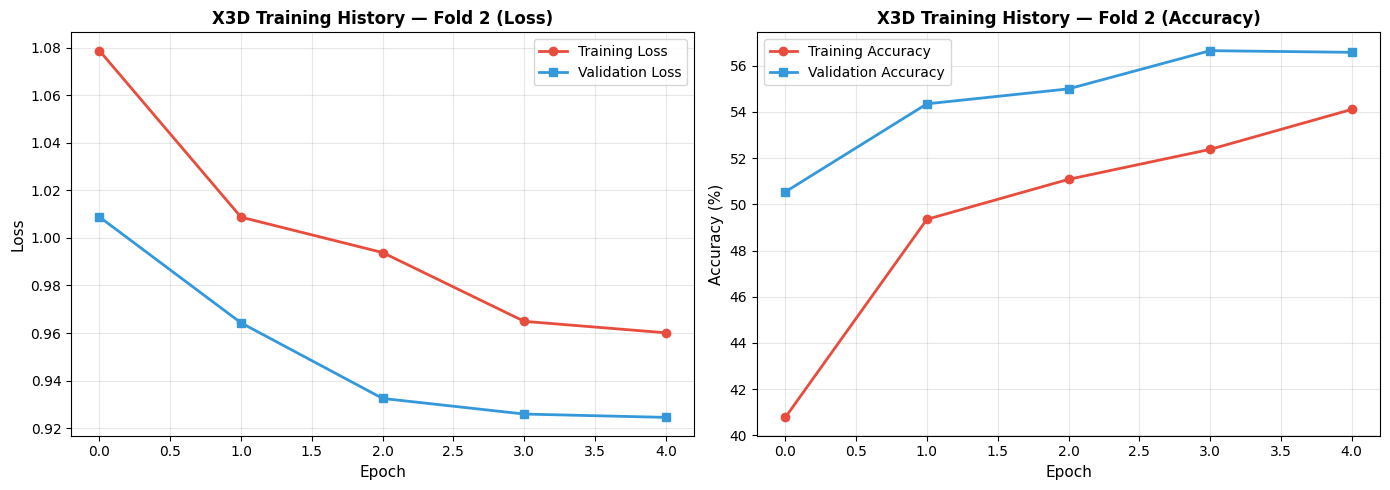


✓ Training history saved


In [39]:
best_result = fold_results[best_fold_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_result['train_losses'], 'o-', label='Training Loss', linewidth=2, color='#e74c3c')
axes[0].plot(best_result['val_losses'],   's-', label='Validation Loss', linewidth=2, color='#3498db')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].set_title(f'X3D Training History — Fold {best_fold} (Loss)', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

axes[1].plot(best_result['train_accs'], 'o-', label='Training Accuracy', linewidth=2, color='#e74c3c')
axes[1].plot(best_result['val_accs'],   's-', label='Validation Accuracy', linewidth=2, color='#3498db')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].set_title(f'X3D Training History — Fold {best_fold} (Accuracy)', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/x3d_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Training history saved")

## 16. Benchmark Summary

In [40]:
from sklearn.metrics import f1_score, precision_score, recall_score

f1       = f1_score(test_labels, test_preds, average='macro')
prec     = precision_score(test_labels, test_preds, average='macro')
rec      = recall_score(test_labels, test_preds, average='macro')

print("\n" + "="*60)
print("X3D BENCHMARK RESULTS")
print("="*60)
print(f"  Model            : X3D-M")
print(f"  Frames per clip  : {NUM_FRAMES_X3D}")
print(f"  Image size       : {IMG_SIZE_X3D}x{IMG_SIZE_X3D}")
print(f"  K-Folds          : {K_FOLDS}")
print(f"  Epochs           : {EPOCHS}")
print(f"  Best Val Fold    : {best_fold} ({best_fold_acc:.2f}%)")
print(f"  Test Accuracy    : {test_acc:.2f}%")
print(f"  Macro F1-Score   : {f1:.4f}")
print(f"  Macro Precision  : {prec:.4f}")
print(f"  Macro Recall     : {rec:.4f}")
print("="*60)


X3D BENCHMARK RESULTS
  Model            : X3D-M
  Frames per clip  : 16
  Image size       : 224x224
  K-Folds          : 2
  Epochs           : 5
  Best Val Fold    : 2 (56.65%)
  Test Accuracy    : 52.03%
  Macro F1-Score   : 0.4837
  Macro Precision  : 0.4985
  Macro Recall     : 0.4829
